In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.sparse as sp
import anndata as ad
import gseapy as gp
from copy import deepcopy
import scanpy.external as sce

# sc.logging.print_version()
sc.settings.verbosity = 3
sc.set_figure_params(figsize=(5,5))

import sys
from pathlib import Path

_start = Path.cwd().resolve()
_repo_root = next((p for p in [_start, *_start.parents] if (p / "chronopack").exists()), _start)
if str(_repo_root) not in sys.path:
    sys.path.insert(0, str(_repo_root))

from chronopack.preprocessing import (
    TIME_GROUP_CATEGORIES,
    add_time_metadata,
    annotate_qc_flags,
    filter_cells_by_qc,
    filter_technical_genes,
    load_time_tagged_anndata,
    map_time_to_group,
)
from chronopack.trajectories import (
    CalculateTerminalFatesAcrossCells,
    PlotHardClusterMassProportionsOverTime,
    cosine_topk_leiden_from_terminal_dist,
    extract_wot_couplings,
    fate_umap_2x2_scanpy,
    mass_retention_plots_and_umap,
    run_wot_transport_workflow,
    sparse_adjacency_from_tmats,
    terminal_fates_from_terminal_clusters,
    topk_csr_rows,
)


In [2]:
sample_paths = [
    '../input/N701_scK562_TNFA_Puromycin_RT2.aligned.sorted.merged.tagged.dge.time_tags.csv.gz',
    '../input/N702_scK562_TNFA_Puromycin_RT3.aligned.sorted.merged.tagged.dge.time_tags.csv.gz',
    '../input/N704_scK562_TNFA_Puromycin_RT4.aligned.sorted.merged.tagged.dge.time_tags.csv.gz',
]

adata = load_time_tagged_anndata(sample_paths, sample_names=['N701', 'N702', 'N704'])
print(adata)


In [6]:
cell_cycle_genes = [x.strip() for x in open('/new-stg/home/alex/ref/gene_sets/regev_lab_cell_cycle_genes.txt')]
s_genes = cell_cycle_genes[:43]
g2m_genes = cell_cycle_genes[43:]
cell_cycle_genes = [x for x in cell_cycle_genes if x in adata.var_names]

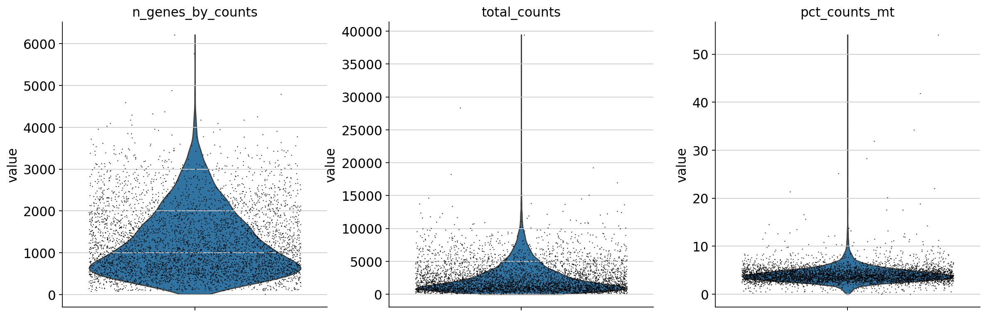

In [7]:
annotate_qc_flags(adata)
sc.pl.violin(adata, ['n_genes_by_counts', 'total_counts', 'pct_counts_mt'], jitter=0.4, multi_panel=True)


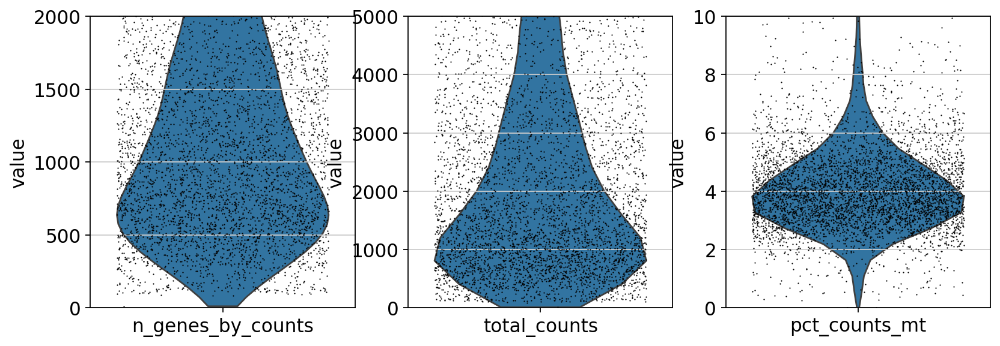

In [8]:
fig, axs = plt.subplots(1, 3, figsize=(12,4))
sc.pl.violin(adata, 'n_genes_by_counts', jitter=0.4, ax=axs[0], show=False)
sc.pl.violin(adata, 'total_counts',      jitter=0.4, ax=axs[1], show=False)
sc.pl.violin(adata, 'pct_counts_mt',     jitter=0.4, ax=axs[2], show=False)

axs[0].set_ylim(0, 2000)    
axs[1].set_ylim(0, 5000)    
axs[2].set_ylim(0, 10)      

plt.show()

In [9]:
adata = filter_cells_by_qc(adata, min_counts=200, max_counts=10000, max_pct_mt=7.5, min_genes=300)
sc.pp.filter_genes(adata, min_cells=3)
print(adata)


filtered out 112 cells that have less than 200 counts
filtered out 49 cells that have more than 10000 counts
filtered out 131 cells that have less than 300 genes expressed


/new-stg/home/alex/miniconda3/envs/wot2/lib/python3.13/site-packages/scanpy/preprocessing/_simple.py:170: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs["n_genes"] = number


filtered out 7899 genes that are detected in less than 3 cells
AnnData object with n_obs × n_vars = 4278 × 18833
    obs: 'COUNTS', 'sample', 'time', 'time_group', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'n_counts', 'n_genes'
    var: 'mt', 'rb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells'


In [10]:
sc.pp.scrublet(adata, batch_key="sample")
adata = adata[~adata.obs['predicted_doublet'], :]

Running Scrublet
filtered out 6405 genes that are detected in less than 3 cells
normalizing counts per cell
    finished (0:00:00)
extracting highly variable genes
    finished (0:00:00)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)
normalizing counts per cell
    finished (0:00:00)
normalizing counts per cell
    finished (0:00:00)
Embedding transcriptomes using PCA...
    using data matrix X directly
Automatically set threshold at doublet score = 0.23
Detected doublet rate = 1.0%
Estimated detectable doublet fraction = 0.3%
Overall doublet rate:
	Expected   = 5.0%
	Estimated  = 275.0%
filtered out 4759 genes that are detected in less than 3 cells
normalizing counts per cell
    finished (0:00:00)
extracting highly variable genes
    finished (0:00:00)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adat

In [11]:
adata.layers['counts'] = adata.X.copy()
sc.pp.normalize_total(adata, target_sum=1e6)
adata.layers['cpm'] = adata.X.copy()
sc.pp.log1p(adata)
adata.layers['log1p'] = adata.X.copy()

sc.pp.highly_variable_genes(adata, batch_key='sample', n_top_genes=3000)
sc.tl.score_genes_cell_cycle(adata, s_genes=s_genes, g2m_genes=g2m_genes)
adata_full = adata.copy()
adata = adata[:, adata.var.highly_variable]

/new-stg/home/alex/.tmp/ipykernel_23907/2219646393.py:1: ImplicitModificationWarning: Setting element `.layers['counts']` of view, initializing view as actual.
  adata.layers['counts'] = adata.X.copy()


normalizing counts per cell
    finished (0:00:00)
extracting highly variable genes
    finished (0:00:02)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)
calculating cell cycle phase
computing score 'S_score'
    finished: added
    'S_score', score of gene set (adata.obs).
    384 total control genes are used. (0:00:00)
computing score 'G2M_score'
    finished: added
    'G2M_score', score of gene set (adata.obs).
    427 total control genes are used. (0:00:00)
-->     'phase', cell cycle phase (adata.obs)


In [12]:
bck = adata.copy()

regressing out ['total_counts', 'pct_counts_mt', 'S_score', 'G2M_score']


/new-stg/home/alex/miniconda3/envs/wot2/lib/python3.13/site-packages/anndata/_core/anndata.py:1138: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


    finished (0:00:00)
computing PCA
    with n_comps=50
    finished (0:00:10)


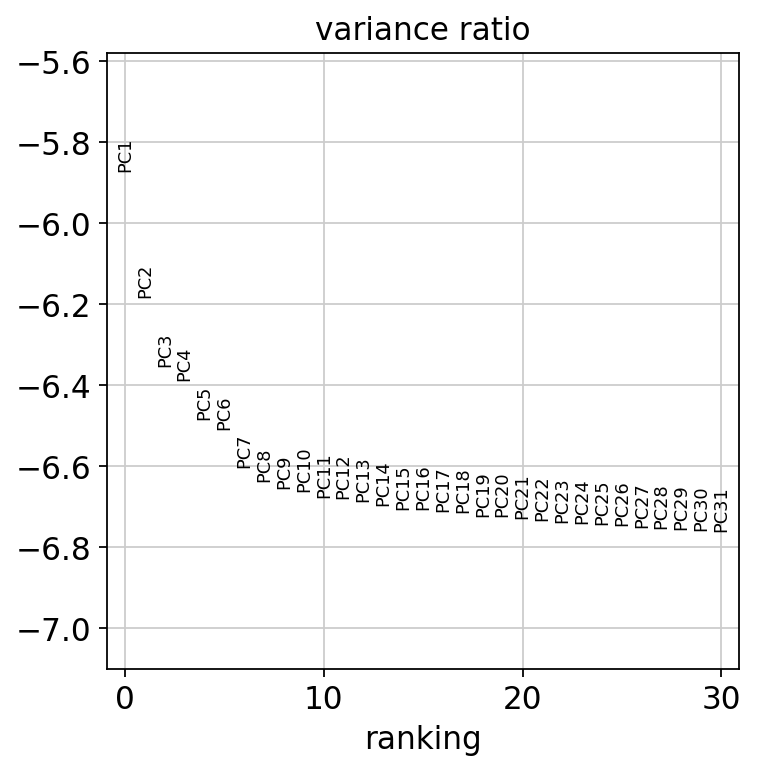

computing neighbors
    using 'X_pca' with n_pcs = 12
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:10)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:11)
running Leiden clustering


/new-stg/home/alex/.tmp/ipykernel_23907/2546391553.py:8: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata, resolution=0.1, key_added='leiden_unintegrated')


    finished: found 1 clusters and added
    'leiden_unintegrated', the cluster labels (adata.obs, categorical) (0:00:01)


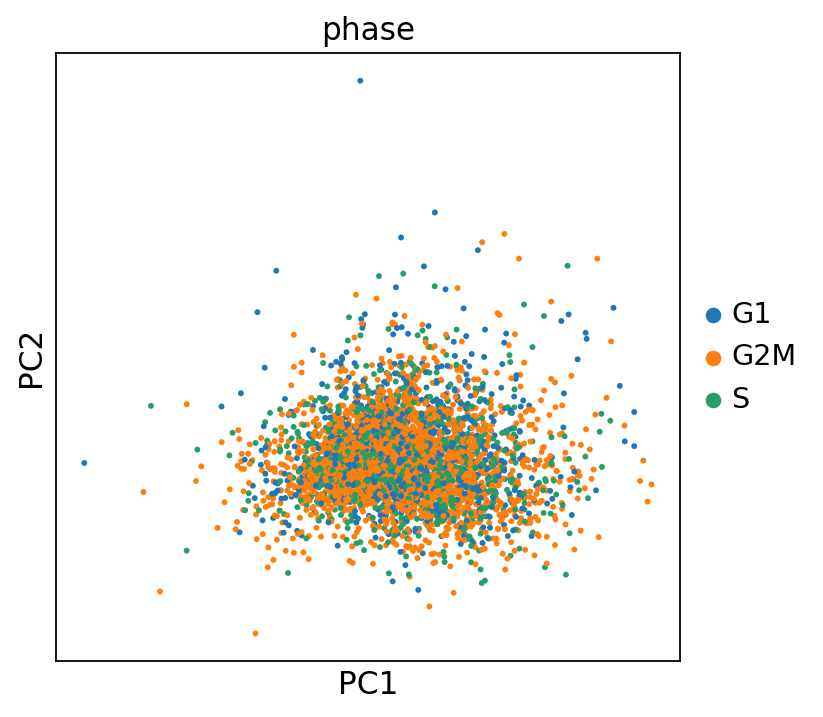

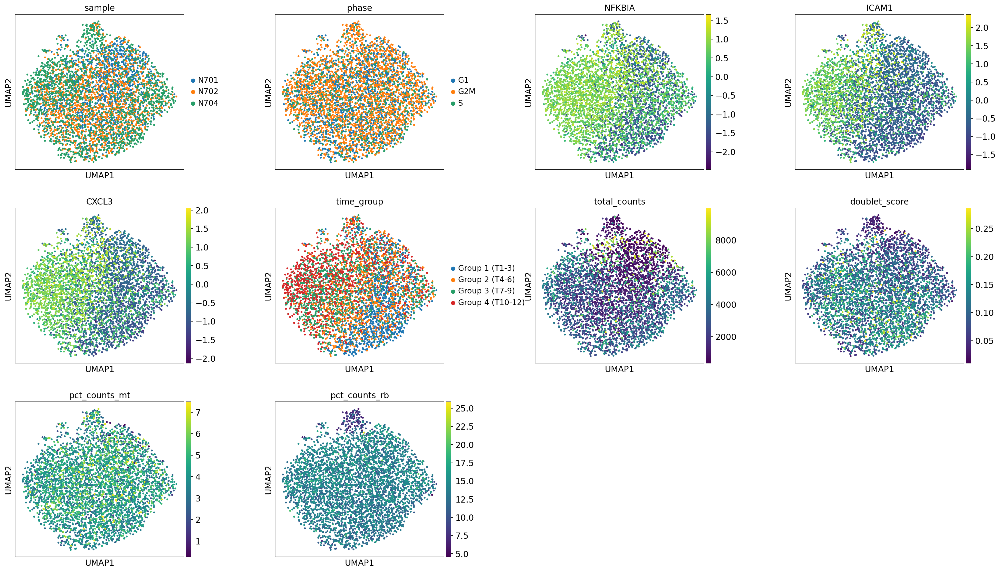

In [13]:
sc.pp.regress_out(adata, ['total_counts', 'pct_counts_mt', 'S_score', 'G2M_score'])
sc.pp.scale(adata)
sc.tl.pca(adata, n_comps=50, svd_solver='arpack')
sc.pl.pca_variance_ratio(adata, n_pcs=30, log=True)
sc.pp.neighbors(adata, n_pcs=12)

sc.tl.umap(adata)
sc.tl.leiden(adata, resolution=0.1, key_added='leiden_unintegrated')

sc.pl.pca_scatter(adata, color='phase')
sc.pl.umap(adata, color=['sample', 'phase', 'NFKBIA', 'ICAM1', 'CXCL3', 'time_group', 'total_counts', 'doublet_score', 'pct_counts_mt', 'pct_counts_rb'], wspace=0.4, size=40, ncols=4)

running Leiden clustering
    finished: found 6 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:02)


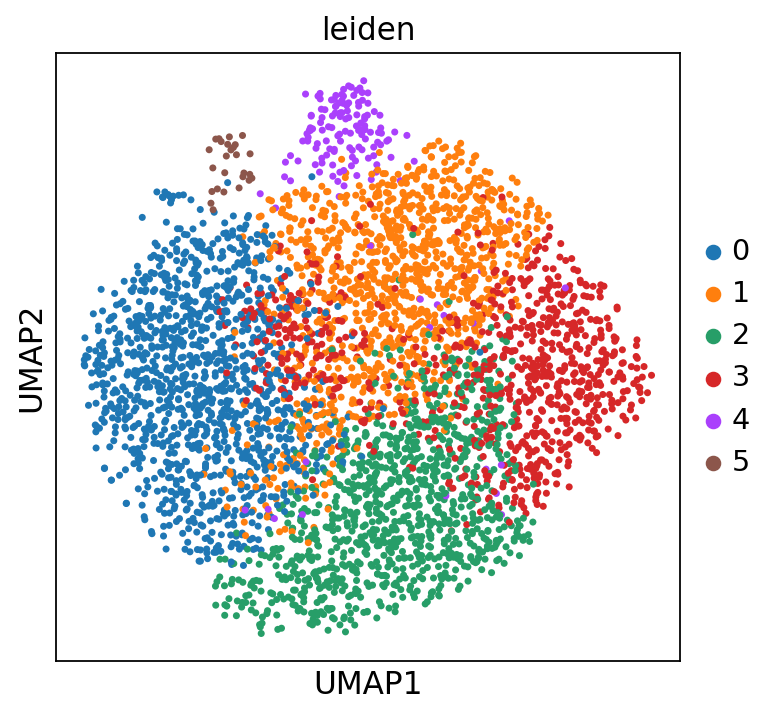

In [14]:
sc.tl.leiden(adata, resolution=0.5)
sc.pl.umap(adata, color=['leiden'], wspace=0.4, size=40, ncols=3)

computing UMAP


/new-stg/home/alex/miniconda3/envs/wot2/lib/python3.13/site-packages/scanpy/tools/_umap.py:187: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[key_uns] = dict(params=dict(a=a, b=b))


    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:11)
running Leiden clustering
    finished: found 1 clusters and added
    'leiden_unintegrated', the cluster labels (adata.obs, categorical) (0:00:01)


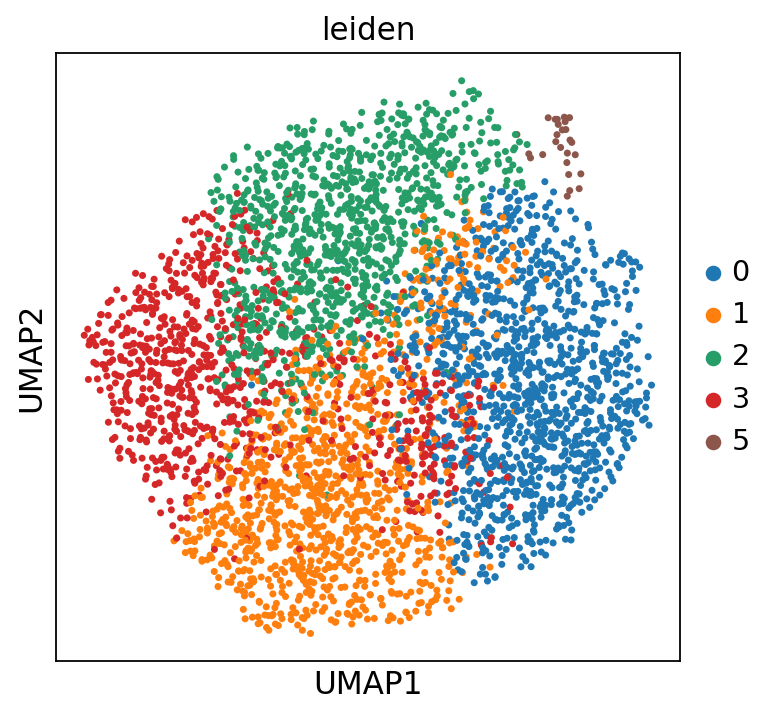

In [15]:
adata = adata[adata.obs['leiden'] != '4', :]

sc.tl.umap(adata)
sc.tl.leiden(adata, resolution=0.1, key_added='leiden_unintegrated')
sc.pl.umap(adata, color=['leiden'], wspace=0.4, size=40, ncols=3)

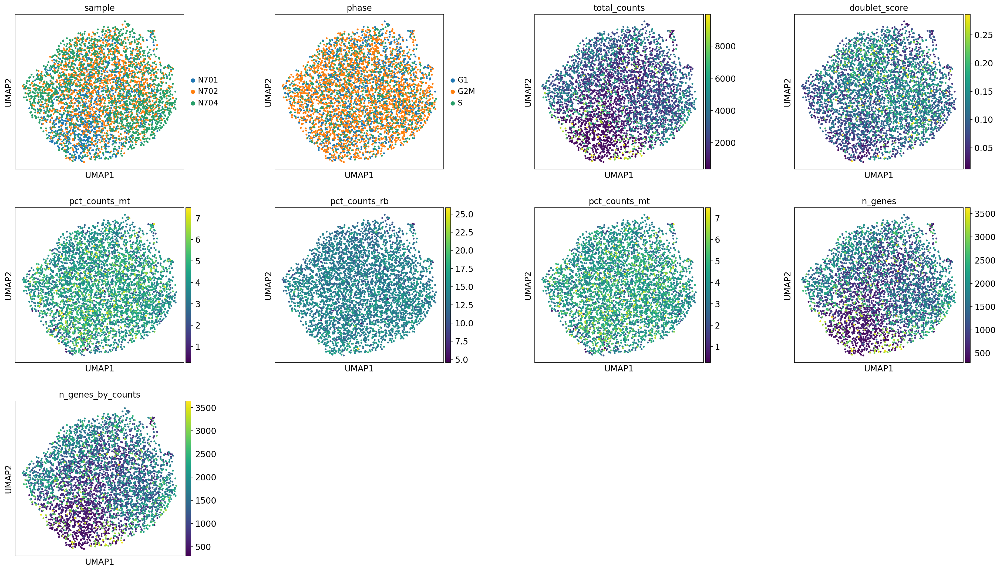

In [16]:
sc.pl.umap(adata, color=['sample', 'phase', 'total_counts', 'doublet_score', 'pct_counts_mt', 'pct_counts_rb', 'pct_counts_mt', 'n_genes', 'n_genes_by_counts'], wspace=0.4, size=40, ncols=4)

In [17]:
bck = bck[adata.obs.index, :]

Standardizing Data across genes.

Found 3 batches

Found 0 numerical variables:
	

Fitting L/S model and finding priors

Finding parametric adjustments



/new-stg/home/alex/miniconda3/envs/wot2/lib/python3.13/site-packages/scanpy/preprocessing/_combat.py:347: RuntimeWarning: divide by zero encountered in divide
  (abs(g_new - g_old) / g_old).max(), (abs(d_new - d_old) / d_old).max()


Adjusting data

computing PCA
    with n_comps=50
    finished (0:00:09)
computing neighbors
    using 'X_pca' with n_pcs = 30
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:00)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:11)
running Leiden clustering
    finished: found 8 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:04)


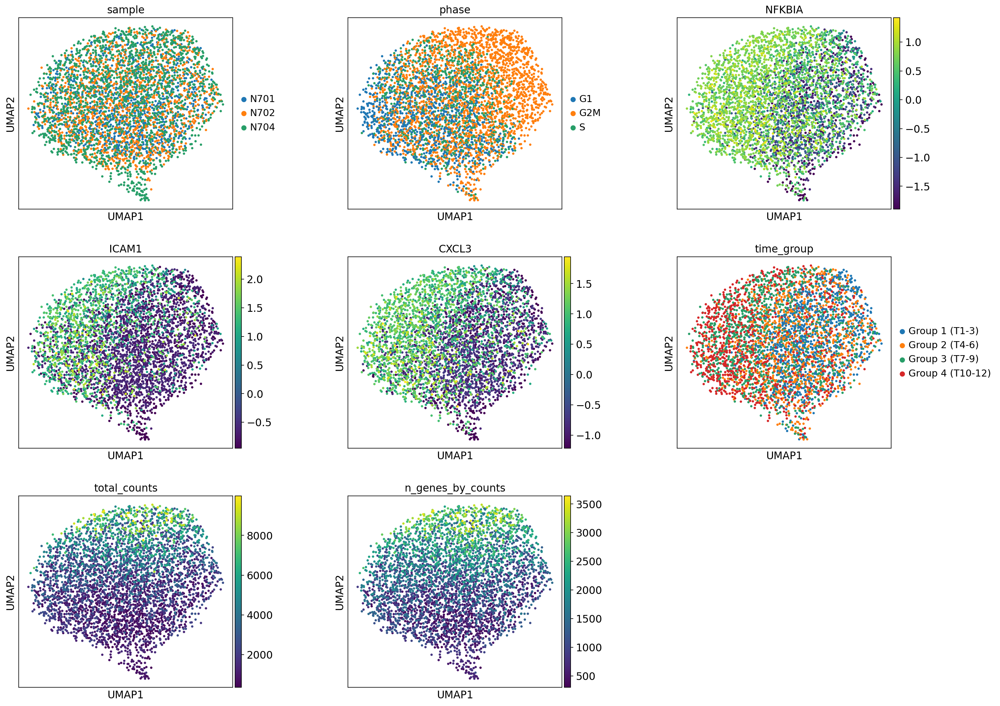

In [18]:
adata_c = bck.copy()

# Batch correction on (log1p + residual) expression
sc.pp.combat(adata_c, key='sample')

# Downstream
sc.pp.scale(adata_c, max_value=10)
sc.tl.pca(adata_c, n_comps=50)
sc.pp.neighbors(adata_c, n_neighbors=15, n_pcs=30)
sc.tl.umap(adata_c); sc.tl.leiden(adata_c)

sc.pl.umap(adata_c, color=['sample', 'phase', 'NFKBIA', 'ICAM1', 'CXCL3', 'time_group', 'total_counts', 'n_genes_by_counts'], wspace=0.4, size=40, ncols=3)

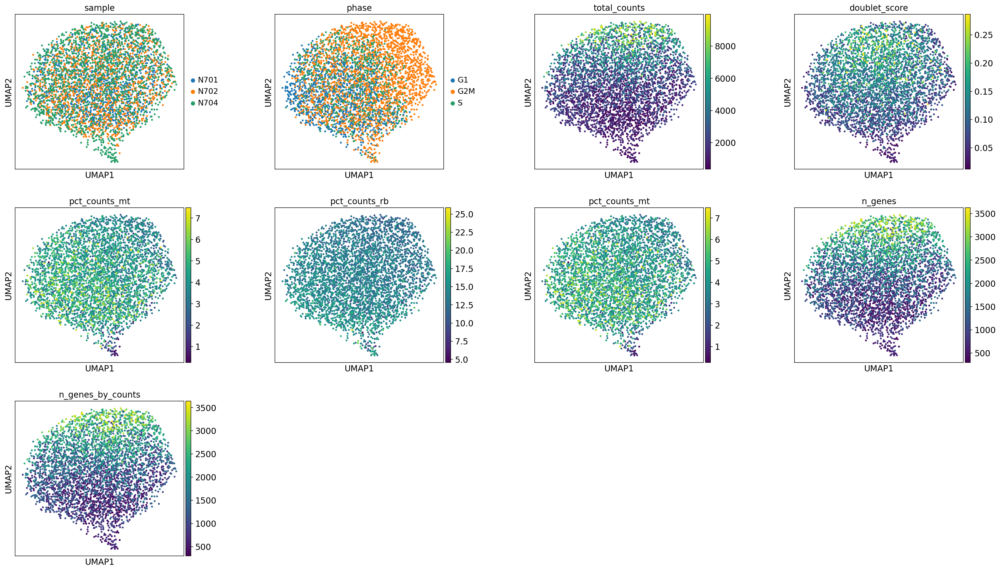

In [19]:
sc.pl.umap(adata_c, color=['sample', 'phase', 'total_counts', 'doublet_score', 'pct_counts_mt', 'pct_counts_rb', 'pct_counts_mt', 'n_genes', 'n_genes_by_counts'], wspace=0.4, size=40, ncols=4)

running Leiden clustering
    finished: found 4 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:01)


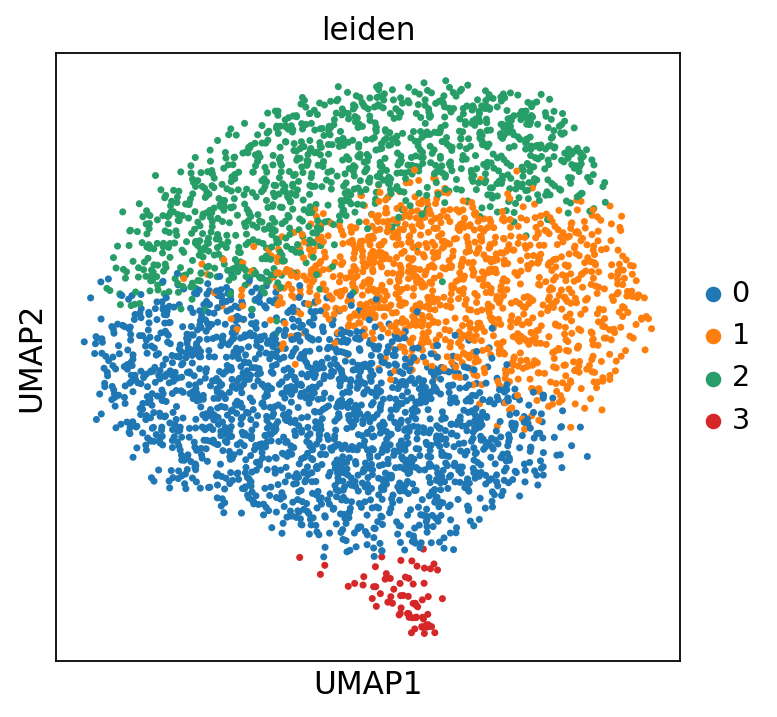

In [20]:
sc.tl.leiden(adata_c, resolution=0.5)
sc.pl.umap(adata_c, color=['leiden'], wspace=0.4, size=40, ncols=3)

In [ ]:
adata_c = adata_c[adata_c.obs['leiden'] != '3', :].copy()


In [22]:
df = adata.obs[['time', 'sample']]
table = pd.crosstab(df['time'], df['sample'])
print(table)

sample  N701  N702  N704
time                    
1        105   127   137
2         92   121   136
3        102    89   122
4         77    97   130
5         77    88   112
6        105   116   131
7        105   127   161
8         88    95   133
9        120   139   171
10        83    93   132
11        85   105   123
12       102   109   165


In [23]:
bck = bck[adata_c.obs.index, :]

In [65]:
adata_b = bck.copy()

sc.pp.regress_out(
    adata_b, keys=['total_counts', 'pct_counts_mt', 'S_score', 'G2M_score']
)
sc.pp.scale(adata_b, max_value=10)
sc.tl.pca(adata_b, n_comps=50)

regressing out ['total_counts', 'pct_counts_mt', 'S_score', 'G2M_score']
    finished (0:00:00)
computing PCA
    with n_comps=50
    finished (0:00:09)


In [67]:
adata_b.X

array([[-5.51799781e-01, -5.48347615e-01, -3.48464431e-01, ...,
        -3.59125412e-02, -1.15556949e-01, -9.57937892e-02],
       [-4.55403754e-02, -2.05242754e-01, -6.87427822e-02, ...,
        -3.38955134e-03, -1.38526939e-02, -2.13019222e-02],
       [-1.09677416e-01, -2.04666014e-01, -8.01222389e-02, ...,
        -1.36940761e-02, -1.91442945e-02, -5.33977404e-02],
       ...,
       [-2.55548554e-01, -3.23580206e-01, -1.62053255e-01, ...,
        -2.09442033e-02, -4.42497718e-02, -4.91174658e-02],
       [ 4.00493325e+00, -3.64247651e-01, -1.57252418e-01, ...,
        -2.46496635e-03, -4.67748848e-02,  7.04363567e-03],
       [-1.15834604e-01, -2.11353568e-01, -6.30494080e-02, ...,
        -1.90547102e-02,  3.36786734e-03, -1.05952068e-02]],
      shape=(4034, 3000))

2026-01-06 13:02:51,550 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-01-06 13:02:53,802 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-01-06 13:02:53,855 - harmonypy - INFO - Iteration 1 of 30
2026-01-06 13:02:55,779 - harmonypy - INFO - Iteration 2 of 30
2026-01-06 13:02:57,536 - harmonypy - INFO - Iteration 3 of 30
2026-01-06 13:02:59,132 - harmonypy - INFO - Iteration 4 of 30
2026-01-06 13:03:00,578 - harmonypy - INFO - Iteration 5 of 30
2026-01-06 13:03:01,785 - harmonypy - INFO - Iteration 6 of 30
2026-01-06 13:03:02,916 - harmonypy - INFO - Iteration 7 of 30
2026-01-06 13:03:04,041 - harmonypy - INFO - Iteration 8 of 30
2026-01-06 13:03:05,176 - harmonypy - INFO - Iteration 9 of 30
2026-01-06 13:03:06,223 - harmonypy - INFO - Iteration 10 of 30
2026-01-06 13:03:07,273 - harmonypy - INFO - Iteration 11 of 30
2026-01-06 13:03:08,319 - harmonypy - INFO - Iteration 12 of 30
2026-01-06 13:03:09,448 - harmonypy - INFO - Converged after

computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:00)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:11)
running Leiden clustering
    finished: found 9 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:02)


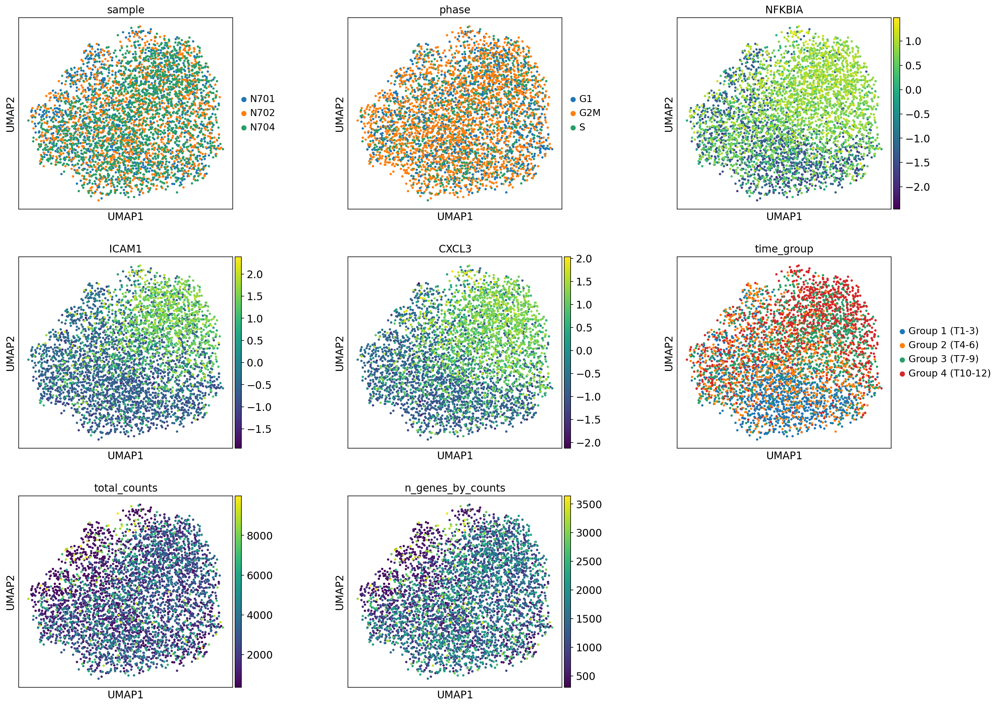

In [69]:
# Batch correction on PCs
sce.pp.harmony_integrate(adata_b, key='sample', max_iter_harmony = 30)          # creates .obsm['X_pca_harmony']
sc.pp.neighbors(adata_b, use_rep='X_pca_harmony', n_neighbors=15, n_pcs=30)
sc.tl.umap(adata_b); sc.tl.leiden(adata_b)

sc.pl.umap(adata_b, color=['sample', 'phase', 'NFKBIA', 'ICAM1', 'CXCL3', 'time_group', 'total_counts', 'n_genes_by_counts'], wspace=0.4, size=40, ncols=3)

In [70]:
adata_b.layers['corrected'] = adata_b.X.copy()
adata_b.layers['corrected']

array([[-5.51799781e-01, -5.48347615e-01, -3.48464431e-01, ...,
        -3.59125412e-02, -1.15556949e-01, -9.57937892e-02],
       [-4.55403754e-02, -2.05242754e-01, -6.87427822e-02, ...,
        -3.38955134e-03, -1.38526939e-02, -2.13019222e-02],
       [-1.09677416e-01, -2.04666014e-01, -8.01222389e-02, ...,
        -1.36940761e-02, -1.91442945e-02, -5.33977404e-02],
       ...,
       [-2.55548554e-01, -3.23580206e-01, -1.62053255e-01, ...,
        -2.09442033e-02, -4.42497718e-02, -4.91174658e-02],
       [ 4.00493325e+00, -3.64247651e-01, -1.57252418e-01, ...,
        -2.46496635e-03, -4.67748848e-02,  7.04363567e-03],
       [-1.15834604e-01, -2.11353568e-01, -6.30494080e-02, ...,
        -1.90547102e-02,  3.36786734e-03, -1.05952068e-02]],
      shape=(4034, 3000))

Harmony corrects PCs, not expression. Let's try ComBat instead for now

In [84]:
adata_c = bck.copy()

sc.pp.combat(adata_c, key='sample') # Batch correction on (log1p + residual) expression
sc.pp.regress_out(adata_c, keys=['total_counts', 'pct_counts_mt', 'S_score', 'G2M_score']) # Remove QC + cell-cycle effects first


Standardizing Data across genes.

Found 3 batches

Found 0 numerical variables:
	

Fitting L/S model and finding priors

Finding parametric adjustments

Adjusting data

regressing out ['total_counts', 'pct_counts_mt', 'S_score', 'G2M_score']
    finished (0:00:00)


In [85]:
adata_c.layers['corrected'] = adata_c.X.copy()

In [86]:
# Downstream
sc.pp.scale(adata_c, max_value=10)
sc.tl.pca(adata_c, n_comps=50)
sc.pp.neighbors(adata_c, n_neighbors=15, n_pcs=30)
sc.tl.umap(adata_c)

computing PCA
    with n_comps=50
    finished (0:00:09)
computing neighbors
    using 'X_pca' with n_pcs = 30
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:00)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:11)


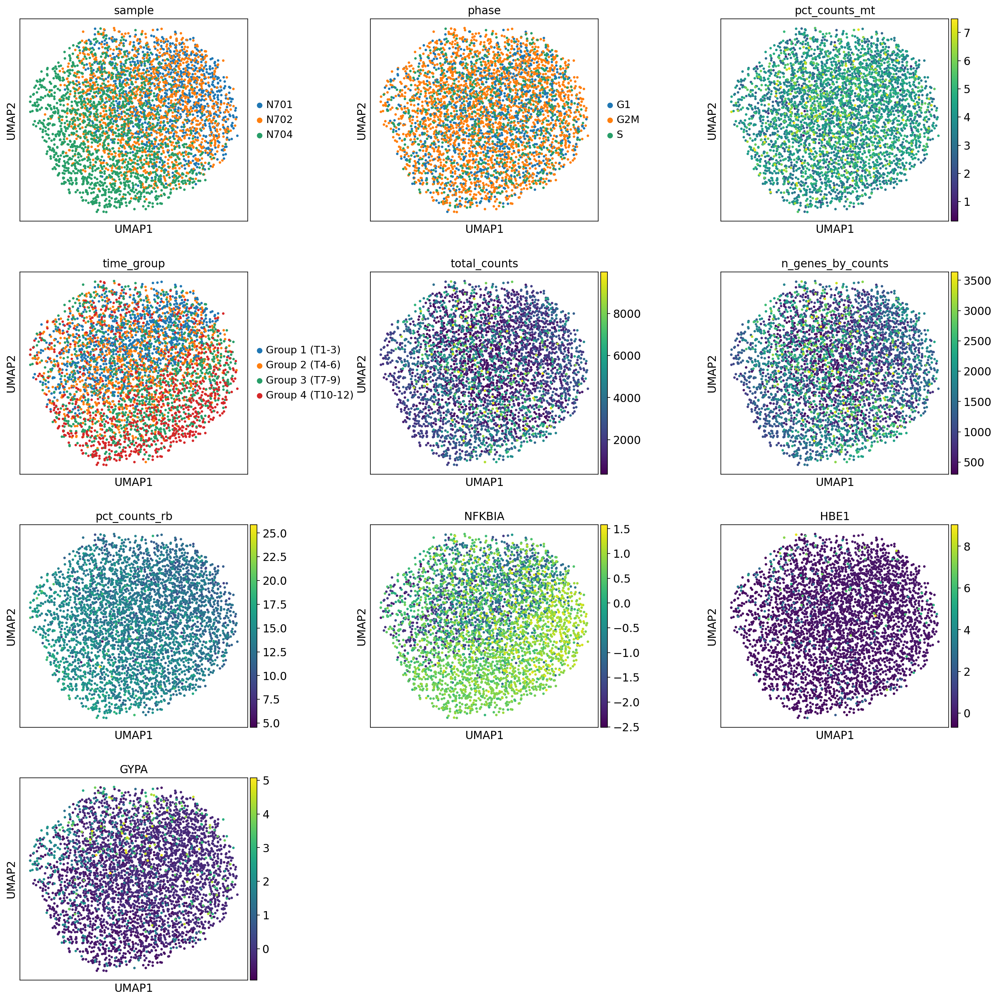

In [87]:
sc.pl.umap(adata_c, color=['sample', 'phase', 'pct_counts_mt', 'time_group', 'total_counts', 'n_genes_by_counts', 'pct_counts_rb', 'NFKBIA', 'HBE1', 'GYPA'], wspace=0.4, size=40, ncols=3)

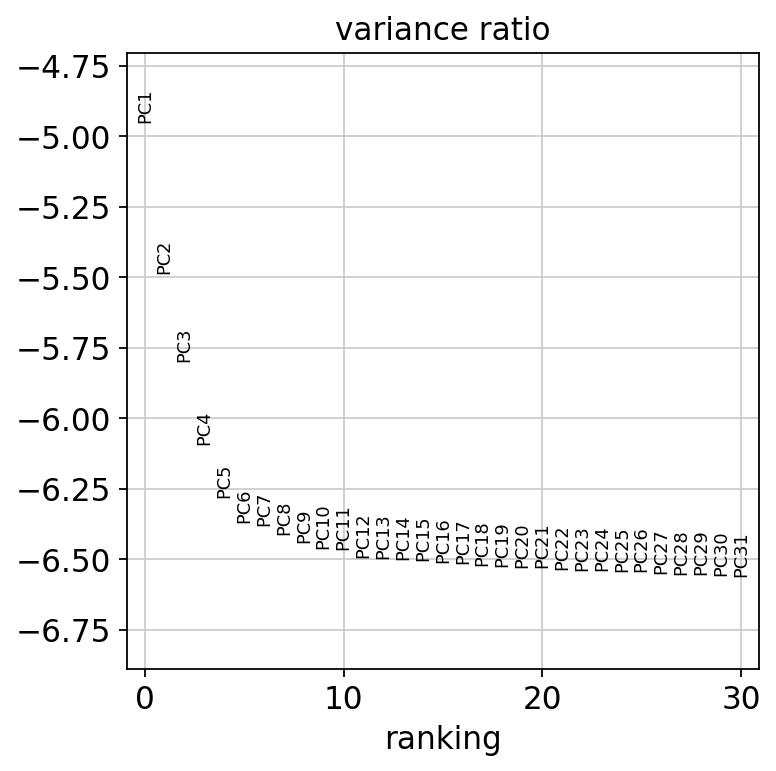

In [88]:
adata = adata_c.copy()
sc.pl.pca_variance_ratio(adata, n_pcs=30, log=True)

regressing out ['total_counts', 'pct_counts_mt', 'S_score', 'G2M_score']
    finished (0:00:00)
computing PCA
    with n_comps=50
    finished (0:00:09)


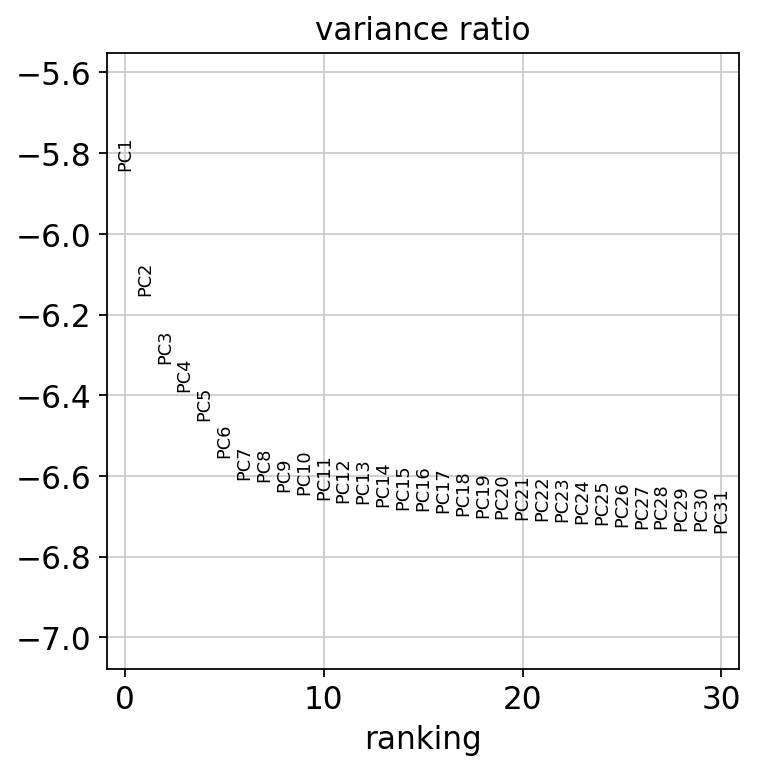

computing neighbors
    using 'X_pca' with n_pcs = 12
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:00)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:10)
running Leiden clustering
    finished: found 1 clusters and added
    'leiden_unintegrated', the cluster labels (adata.obs, categorical) (0:00:01)


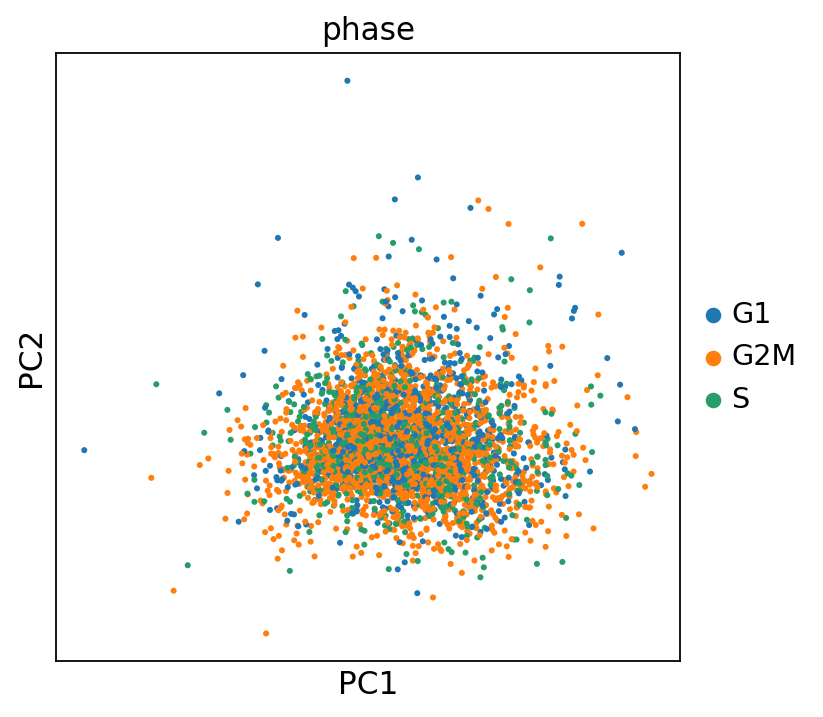

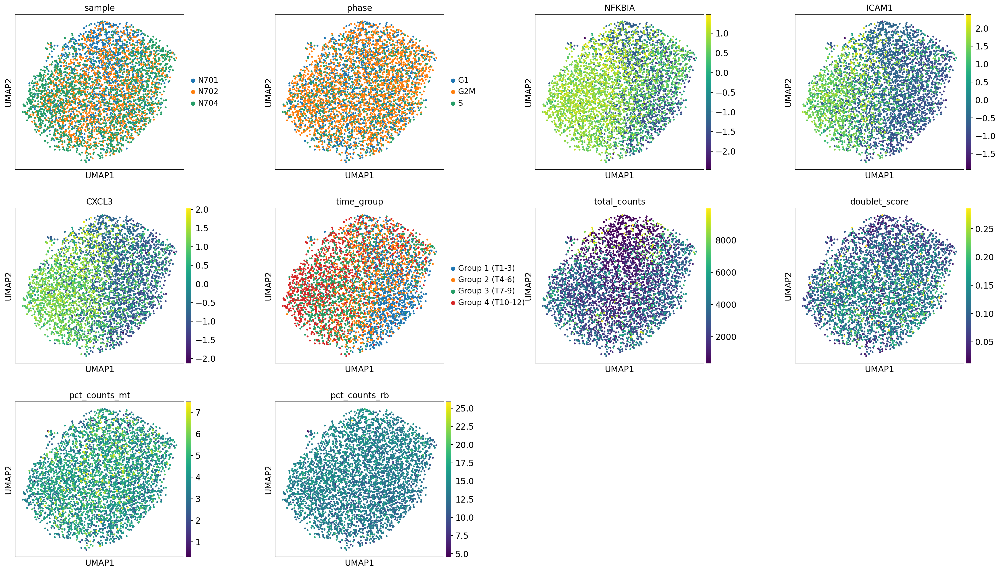

In [123]:
sc.pp.regress_out(adata, ['total_counts', 'pct_counts_mt', 'S_score', 'G2M_score'])
sc.pp.scale(adata)
sc.tl.pca(adata, n_comps=50, svd_solver='arpack')
sc.pl.pca_variance_ratio(adata, n_pcs=30, log=True)
sc.pp.neighbors(adata, n_pcs=12)

sc.tl.umap(adata)
sc.tl.leiden(adata, resolution=0.1, key_added='leiden_unintegrated')

sc.pl.pca_scatter(adata, color='phase')
sc.pl.umap(adata, color=['sample', 'phase', 'NFKBIA', 'ICAM1', 'CXCL3', 'time_group', 'total_counts', 'doublet_score', 'pct_counts_mt', 'pct_counts_rb'], wspace=0.4, size=40, ncols=4)

# Waddington‑OT (Transport maps)

In [94]:
adata.X = adata.layers['corrected']

wot_out = run_wot_transport_workflow(
    adata,
    tmap_dir='tmaps_sc/',
    ot_model_kwargs=dict(epsilon=0.05, lambda1=1, lambda2=50, growth_iters=3, day_field='time'),
    compute_transport_maps=True,
    transition_topk=30,
    symmetrize='average',
    use_unpruned_as_pruned=True,
    graph_key='ot_graph',
    umap_key='X_ot_umap',
    umap_random_state=10,
)

tmaps = wot_out['tmaps']
transitions_long = wot_out['transitions_long']
tmats = wot_out['tmats']
T_full = wot_out['T_full']
T_pruned = wot_out['T_pruned']
adata.obsp['t_pruned'] = T_pruned
T_sym = wot_out['T_sym']
key = 'X_ot_umap'
adata.obsm['X_umap'][:, 0] *= -1
adata.obsm[key] = adata.obsm['X_umap'].copy()


In [130]:
adata

AnnData object with n_obs × n_vars = 4034 × 3000
    obs: 'COUNTS', 'sample', 'time', 'time_group', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'n_counts', 'n_genes', 'doublet_score', 'predicted_doublet', 'S_score', 'G2M_score', 'phase', 'leiden_unintegrated', 'metacell'
    var: 'mt', 'rb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection', 'mean', 'std'
    uns: 'scrublet', 'log1p', 'hvg', 'pca', 'neighbors', 'umap', 'leiden_unintegrated', 'phase_colors', 'sample_colors', 'time_group_colors'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'counts', 'cpm', 'log1p'
    obsp: 'distances', 'connectivities'

In [95]:
# --- Visualize successor representation S for a single cell on an embedding ---
def plot_sr_for_cell(
    adata,
    S,
    cell=None,                  # int row index OR obs name (string). If None: random
    basis="umap",               # embedding name; expects adata.obsm['X_'+basis]
    colname="_sr_score",        # temp column in adata.obs
    normalize="l1",             # 'l1' | 'none' | 'z' (z-score)
    clip_quantile=0.995,        # clip color scale at this quantile (None = no clip)
    cmap="magma",
    size=8,
    keep_column=False,          # keep the column in adata.obs after plotting?
    ax=None,
    title=None,
    seed=0,
):
    import numpy as np, scipy.sparse as sp, scanpy as sc, matplotlib.pyplot as plt

    # --- pick the cell ---
    n = adata.n_obs
    if sp.issparse(S):
        S = S.tocsr()
    assert S.shape == (n, n), "S must be n_obs x n_obs"

    if cell is None:
        rng = np.random.default_rng(seed)
        i = int(rng.integers(0, n))
    elif isinstance(cell, str):
        i = int(adata.obs_names.get_loc(cell))
    else:
        i = int(cell)

    # --- row vector (successor weights) ---
    s = S.getrow(i).toarray().ravel() if sp.isspmatrix(S) else np.asarray(S[i]).ravel()

    # normalize (S from a power series often isn’t row-stochastic)
    if normalize == "l1":
        den = s.sum()
        if den > 0:
            s = s / den
    elif normalize == "z":
        mu, sd = np.nanmean(s), np.nanstd(s)
        if sd > 0:
            s = (s - mu) / sd
    # else: 'none'

    # choose vmax via quantile (ignore zeros so the scale adapts to the support of s)
    if clip_quantile is not None and np.isfinite(clip_quantile):
        pos = s[s > 0]
        vmax = np.quantile(pos, clip_quantile) if pos.size else s.max()
    else:
        vmax = None

    # add to obs and plot
    adata.obs[colname] = s
    if ax is None:
        _, ax = plt.subplots(1, 1, figsize=(6.2, 5.6))

    src = adata.obs_names[i]
    sc.pl.embedding(
        adata,
        basis=basis,
        color=[colname],
        color_map=cmap,
        vmin=0,
        vmax=vmax,
        na_color="lightgrey",
        size=size,
        frameon=False,
        ax=ax,
        title=title or f"{basis.upper()} — successor mass from '{src}'",
        show=False,
    )

    # highlight the source cell
    xy = adata.obsm[f"X_{basis}"][i]
    ax.scatter([xy[0]], [xy[1]], s=80, c="none", edgecolors="cyan", linewidths=2.0, zorder=5)

    if not keep_column:
        del adata.obs[colname]
    plt.show()
    return src, i

In [721]:
# Row-stochastic P from your T_pruned
P = T_pruned.tocsr().astype(float)
rs = np.asarray(P.sum(axis=1)).ravel(); rs[rs==0] = 1.0
P = sp.diags(1/rs) @ P

# Successor representation S = sum_{k=1..K} gamma^k P^k  (K≈8–12, gamma≈0.85–0.95)
K, gamma = 12, 0.9
S, Pk, w = sp.csr_matrix(P.shape), P.copy(), gamma
for _ in range(1, K+1):
    S += w * Pk
    Pk = Pk @ P
    w *= gamma

# W = 0.5 * (S+S.T)
W = S.maximum(S.T)
W = topk_csr_rows(W, 1000)

W.setdiag(1e-12)            # tiny self loop to avoid zero-degree rows
W.eliminate_zeros()

In [ ]:
# Compute sparse terminal-cell fate distributions for every cell.
# Stores adata.obsm["terminal_cell_dist"] and adata.uns["terminal_cell_dist_idx_last"].
CalculateTerminalFatesAcrossCells(adata, T_pruned, topk=200)

In [ ]:
W_pruned = cosine_topk_leiden_from_terminal_dist(adata, dist_key="terminal_cell_dist", topk=500, random_state=0)
sc.tl.leiden(
    adata,
    adjacency=W_pruned.tocsr(),
    directed=False,
    use_weights=True,
    resolution=0.5,
    key_added="traj_leiden_sr",
    random_state=0,
)


In [ ]:
time_key = "time"
traj_key = "traj_leiden_sr"
fate_key = "fate_probs_traj_last"
basis = "X_ot_umap" if "X_ot_umap" in adata.obsm else ("X_umap" if "X_umap" in adata.obsm else "X_pca")

# Aggregate terminal-cell distributions by terminal trajectory cluster.
F, fate_names = terminal_fates_from_terminal_clusters(
    adata,
    terminal_cluster_key=traj_key,
    out_key=fate_key,
)
fate_names = [str(x) for x in fate_names]

# Preserve legacy column names used by exploratory plots/downstream checks.
for fate in fate_names:
    adata.obs[f"fate_p{fate}_traj_last"] = adata.obs[f"{fate_key}_{fate}"].astype(np.float32)

hard = np.asarray(fate_names, dtype=object)[np.asarray(F).argmax(axis=1)]
adata.obs["fate_hard_traj_last_argmax"] = pd.Categorical(hard.astype(str), categories=fate_names)

P = np.asarray(F, dtype=np.float64)
P = P / np.maximum(P.sum(axis=1, keepdims=True), 1e-12)
adata.obs["fate_entropy_traj_last"] = (-(P * np.log(P + 1e-12)).sum(axis=1)).astype(np.float32)
adata.obs["fate_maxprob_traj_last"] = P.max(axis=1).astype(np.float32)

print(f"Stored adata.obsm['{fate_key}'] with fates: {fate_names}")

# Standard ChronoPack fate visualization plus the legacy hard-call view.
which_two = (0, 1) if len(fate_names) >= 2 else (0, 0)
fate_umap_2x2_scanpy(
    adata,
    fate_key=fate_key,
    fate_names_key=f"{fate_key}_fates",
    umap_basis=basis,
    fate_obs_prefix="fate_traj_last",
    which_two=which_two,
    max_entropy_norm=False,
    size=25,
)

sc.pl.embedding(
    adata,
    basis=basis,
    color=[time_key, traj_key, "fate_maxprob_traj_last", "fate_hard_traj_last_argmax"],
    ncols=4,
    size=25,
    cmap="viridis",
)

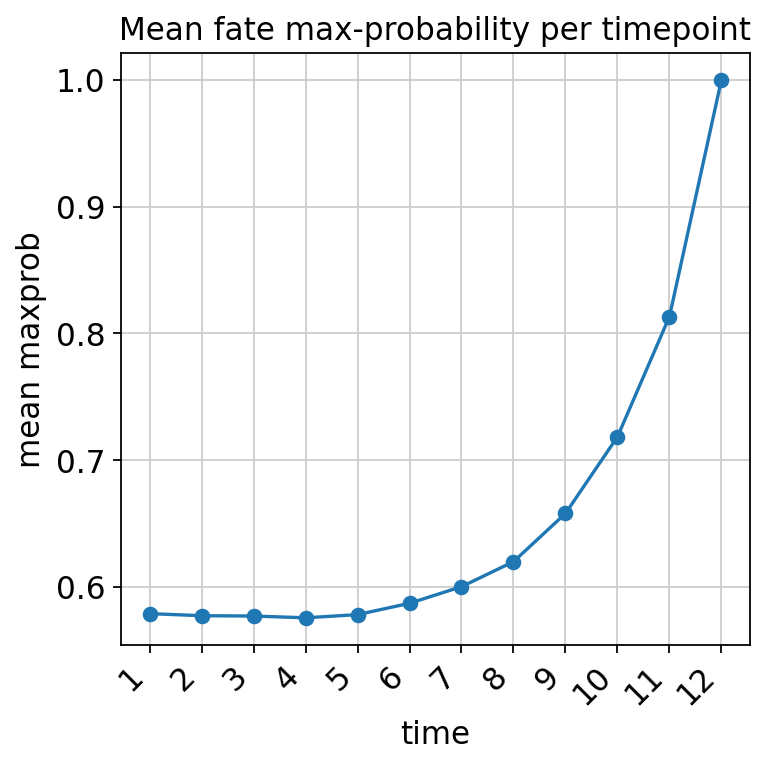

time=1 | n=  363 | mean_maxprob=0.5790
time=2 | n=  348 | mean_maxprob=0.5773
time=3 | n=  307 | mean_maxprob=0.5771
time=4 | n=  299 | mean_maxprob=0.5757
time=5 | n=  269 | mean_maxprob=0.5782
time=6 | n=  340 | mean_maxprob=0.5871
time=7 | n=  386 | mean_maxprob=0.6002
time=8 | n=  310 | mean_maxprob=0.6199
time=9 | n=  426 | mean_maxprob=0.6580
time=10 | n=  306 | mean_maxprob=0.7184
time=11 | n=  310 | mean_maxprob=0.8132
time=12 | n=  370 | mean_maxprob=1.0000


In [736]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# Mean fate max-probability per timepoint
#   - uses adata.obs['fate_maxprob_traj_last']
# ============================================================

time_key = "time"
col = "fate_maxprob_traj_last"

assert time_key in adata.obs, f"Need adata.obs['{time_key}']"
assert col in adata.obs, f"Need adata.obs['{col}'] (run the entropy cell first)."

t = adata.obs[time_key]
x = adata.obs[col].to_numpy(dtype=float)

# ordered time levels
if hasattr(t, "cat"):
    time_levels = list(t.cat.categories)
else:
    time_levels = sorted(pd.unique(t))

tt = t.to_numpy().astype(object)

means = []
ns = []
levels = []
for lvl in time_levels:
    ii = np.where(tt == lvl)[0]
    if ii.size == 0:
        continue
    means.append(float(np.mean(x[ii])))
    ns.append(int(ii.size))
    levels.append(lvl)

plt.figure()
plt.plot(np.arange(len(means)), means, marker="o")
plt.xticks(np.arange(len(means)), [str(l) for l in levels], rotation=45, ha="right")
plt.xlabel("time")
plt.ylabel("mean maxprob")
plt.title("Mean fate max-probability per timepoint")
plt.tight_layout()
plt.show()

# Optional: print counts
for lvl, m, n in zip(levels, means, ns):
    print(f"time={lvl} | n={n:5d} | mean_maxprob={m:.4f}")

In [745]:
tmp = adata.obsp["W_terminal_cosine_topk"].copy()

/new-stg/home/alex/miniconda3/envs/wot2/lib/python3.13/site-packages/scipy/sparse/_index.py:210: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_arrayXarray(i, j, x)


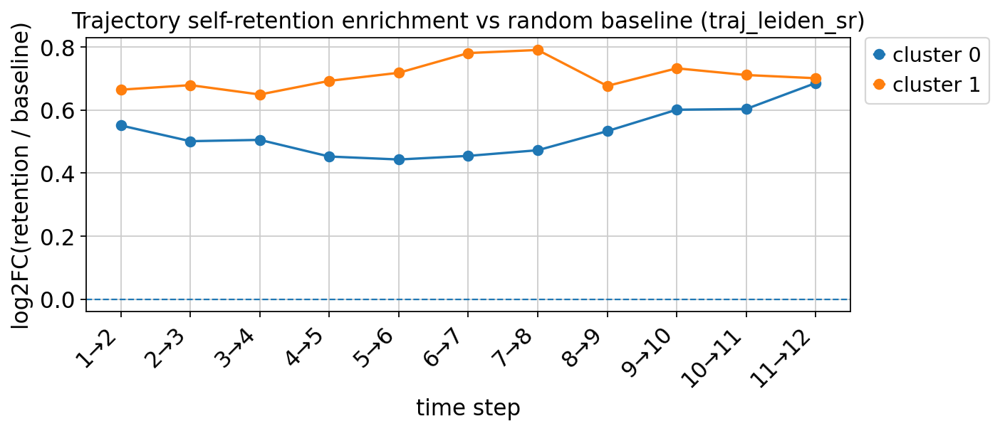

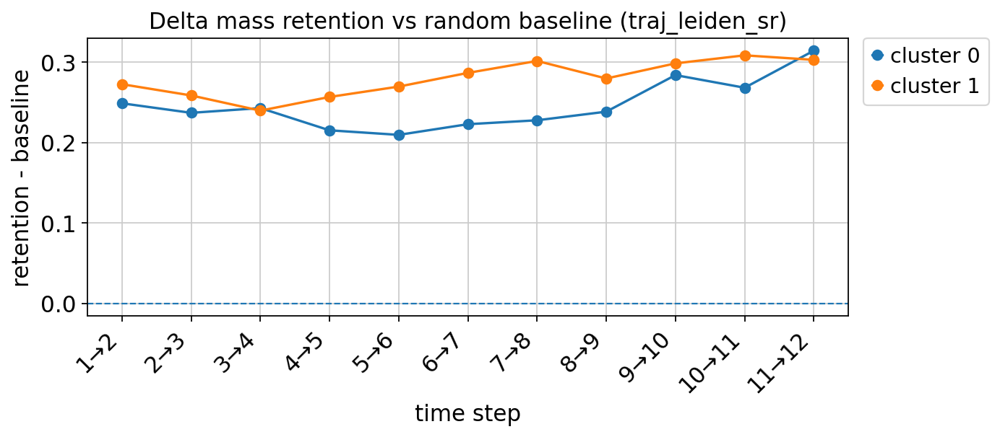

In [784]:
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt

# ============================================================
# logFC (retention vs random baseline) over time for traj_leiden_sr
#   logFC_c(t) = log( retention_c(t) / baseline_c(t) )
#   (set log_base = 2 for log2FC; default = natural log)
#
#   retention_c(t): fraction of mass from cluster c @ time t that lands in cluster c @ time t+1
#   baseline_c(t): expected fraction if destinations were random given cluster size at t+1
#                  = frac of cells in cluster c at time t+1
#
#   Plots logFC over time for clusters 0 and 1.
# ============================================================

time_key = "time"
traj_key = "traj_leiden_sr"
log_base = 2.0          # set to np.e for natural log, 2 for log2FC
eps = 1e-12             # for numerical stability
T = T_pruned.tocsr().astype(np.float64)

assert time_key in adata.obs, f"Need adata.obs['{time_key}']"
assert traj_key in adata.obs, f"Need adata.obs['{traj_key}']"
assert sp.issparse(T) and T.shape == (adata.n_obs, adata.n_obs)

# --- enforce row-stochastic on full T (safe) ---
rs = np.asarray(T.sum(axis=1)).ravel()
zero = rs == 0
if np.any(zero):
    T = T.copy().tocsr()
    T[zero, zero] = 1.0
    rs = np.asarray(T.sum(axis=1)).ravel()
T = sp.diags(1.0 / (rs + 1e-15)) @ T

# --- time bins ---
t = adata.obs[time_key]
if hasattr(t, "cat"):
    time_levels = list(t.cat.categories)
else:
    time_levels = sorted(pd.unique(t))
tt = t.to_numpy().astype(object)

idx_by_time_all = [np.where(tt == lvl)[0] for lvl in time_levels]
idx_by_time = [ii for ii in idx_by_time_all if ii.size > 0]
time_levels_nonempty = [lvl for lvl, ii in zip(time_levels, idx_by_time_all) if ii.size > 0]
assert len(idx_by_time) >= 2, "Need at least 2 timepoints"

lab = adata.obs[traj_key].astype(str).to_numpy()
clusters = ["0", "1"]

n_steps = len(idx_by_time) - 1
ret = {c: np.full(n_steps, np.nan, dtype=float) for c in clusters}
base = {c: np.full(n_steps, np.nan, dtype=float) for c in clusters}

for ti in range(n_steps):
    idx_src = idx_by_time[ti]
    idx_dst = idx_by_time[ti + 1]

    A = T[idx_src, :][:, idx_dst].tocsr()  # (n_src x n_dst)
    denom = np.asarray(A.sum(axis=1)).ravel()

    dst_lab = lab[idx_dst]
    dst_total = idx_dst.size

    for c in clusters:
        src_mask = (lab[idx_src] == c)
        if not np.any(src_mask) or dst_total == 0:
            continue

        src_rows = np.where(src_mask)[0]
        A_c = A[src_rows, :]

        denom_c = denom[src_rows]
        total_out = float(denom_c.sum())
        if total_out <= 0:
            continue

        # baseline = fraction of DESTINATION cells that are in cluster c
        base_c = float(np.mean(dst_lab == c))
        base[c][ti] = base_c

        # retention mass into same-labeled destination cells
        dst_mask_c = (dst_lab == c)
        if np.any(dst_mask_c):
            same_mass = float(A_c[:, np.where(dst_mask_c)[0]].sum())
        else:
            same_mass = 0.0

        ret[c][ti] = same_mass / total_out

# --- compute logFC with clipping ---
def _log_fc(a, b, eps=1e-12, log_base=2.0):
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    ratio = (np.clip(a, eps, None) / np.clip(b, eps, None))
    if log_base == np.e:
        return np.log(ratio)
    else:
        return np.log(ratio) / np.log(log_base)

logFC = {c: _log_fc(ret[c], base[c], eps=eps, log_base=log_base) for c in clusters}

# --- plot ---
x = np.arange(n_steps)
xlab = [f"{time_levels_nonempty[i]}→{time_levels_nonempty[i+1]}" for i in range(n_steps)]
ylabel = "log2FC(retention / baseline)" if log_base == 2.0 else "logFC(retention / baseline)"

plt.figure(figsize=(9, 4))
for c in clusters:
    plt.plot(x, logFC[c], marker="o", linewidth=1.5, label=f"cluster {c}")
plt.axhline(0.0, linestyle="--", linewidth=1.0)  # ratio=1 baseline
plt.xticks(x, [str(s) for s in xlab], rotation=45, ha="right")
plt.xlabel("time step")
plt.ylabel(ylabel)
plt.title(f"Trajectory self-retention enrichment vs random baseline ({traj_key})")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0)
plt.tight_layout()
plt.show()

# Optional: store in adata.uns for later reuse
adata.uns["traj_retention"] = {"ret": ret, "base": base, "logFC": logFC, "time_steps": [str(s) for s in xlab]}

# --- delta ---
delta = {c: (ret[c] - base[c]) for c in clusters}

# --- plot ---
x = np.arange(n_steps)
xlab = [f"{time_levels_nonempty[i]}→{time_levels_nonempty[i+1]}" for i in range(n_steps)]

plt.figure(figsize=(9, 4))
for c in clusters:
    plt.plot(x, delta[c], marker="o", linewidth=1.5, label=f"cluster {c}")
plt.axhline(0.0, linestyle="--", linewidth=1.0)  # retention == baseline
plt.xticks(x, [str(s) for s in xlab], rotation=45, ha="right")
plt.xlabel("time step")
plt.ylabel("retention - baseline")
plt.title(f"Delta mass retention vs random baseline ({traj_key})")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0)
plt.tight_layout()
plt.show()

# optional: stash
adata.uns["traj_retention_delta"] = {"delta": delta, "ret": ret, "base": base, "time_steps": [str(s) for s in xlab]}

/new-stg/home/alex/miniconda3/envs/wot2/lib/python3.13/site-packages/scipy/sparse/_index.py:210: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_arrayXarray(i, j, x)


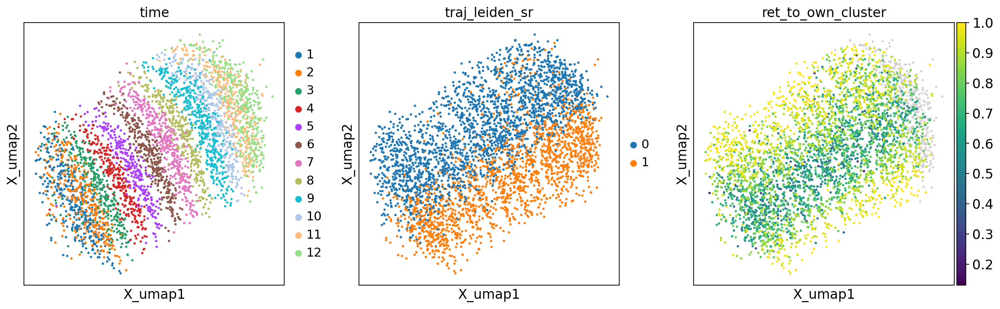


Per-time retention-to-own summary:
      count      mean    median       std
time                                     
1       363  0.764223  0.779214  0.164161
2       348  0.751730  0.761630  0.167011
3       307  0.752404  0.770885  0.179019
4       299  0.745741  0.771721  0.185276
5       269  0.748227  0.755810  0.172643
6       340  0.765994  0.793730  0.174304
7       386  0.774615  0.794974  0.175481
8       310  0.761037  0.768385  0.170797
9       426  0.793766  0.830334  0.167264
10      306  0.787778  0.821351  0.162747
11      310  0.809100  0.827234  0.146604
12        0       NaN       NaN       NaN


In [788]:
import numpy as np
import pandas as pd
import scipy.sparse as sp
import scanpy as sc

# ============================================================
# Per-cell "mass retention to own cluster" on UMAP
#   For each cell i at time t (except last timepoint):
#     let c_i = traj cluster label (0/1)
#     look at forward mass from i -> cells at time t+1 via T_pruned block
#     retention_i = mass landing in cluster c_i at t+1 / total mass from i to t+1
#
#   Stores:
#     adata.obs['ret_to_own_cluster']  (float in [0,1], NaN for last timepoint or no outgoing mass)
#     adata.obs['ret_to_other_cluster'] (=1-ret, when defined)
# ============================================================

time_key = "time"
traj_key = "traj_leiden_sr"  # must be '0'/'1' for all cells
basis = "X_umap" if "X_umap" in adata.obsm else ("X_ot_umap" if "X_ot_umap" in adata.obsm else "X_pca")

assert time_key in adata.obs, f"Need adata.obs['{time_key}']"
assert traj_key in adata.obs, f"Need adata.obs['{traj_key}']"
assert "T_pruned" in globals(), "Need T_pruned in scope."
assert sp.issparse(T_pruned), "T_pruned must be sparse."

T = T_pruned.tocsr().astype(np.float64)

# row-stochastic (safe)
rs = np.asarray(T.sum(axis=1)).ravel()
zero = rs == 0
if np.any(zero):
    T = T.copy().tocsr()
    T[zero, zero] = 1.0
    rs = np.asarray(T.sum(axis=1)).ravel()
T = sp.diags(1.0 / (rs + 1e-15)) @ T

# time bins
t = adata.obs[time_key]
tt = t.to_numpy().astype(object)
time_levels = list(t.cat.categories) if hasattr(t, "cat") else sorted(pd.unique(tt))
idx_by_time_all = [np.where(tt == lvl)[0] for lvl in time_levels]
idx_by_time = [ii for ii in idx_by_time_all if ii.size > 0]
time_levels_nonempty = [lvl for lvl, ii in zip(time_levels, idx_by_time_all) if ii.size > 0]
assert len(idx_by_time) >= 2

# labels 0/1
lab = adata.obs[traj_key].astype(str).to_numpy()
if not np.all(np.isin(lab, ["0", "1"])):
    raise ValueError(f"{traj_key} must contain only '0'/'1'.")
lab01 = lab.astype(int)

ret_own = np.full(adata.n_obs, np.nan, dtype=np.float32)

for ti in range(len(idx_by_time) - 1):
    idx_src = idx_by_time[ti]
    idx_dst = idx_by_time[ti + 1]

    A = T[idx_src, :][:, idx_dst].tocsr()  # (n_src x n_dst)
    denom = np.asarray(A.sum(axis=1)).ravel()  # should be ~1, but keep general

    dst_lab01 = lab01[idx_dst]
    dst_mask0 = (dst_lab01 == 0)
    dst_mask1 = ~dst_mask0

    # mass to cluster0 / cluster1 for each source cell
    m0 = np.asarray(A[:, dst_mask0].sum(axis=1)).ravel()
    m1 = np.asarray(A[:, dst_mask1].sum(axis=1)).ravel()

    # pick "own" mass based on src label
    own = np.where(lab01[idx_src] == 0, m0, m1)

    # retention fraction (guard against denom==0)
    ok = denom > 0
    r = np.full(idx_src.size, np.nan, dtype=np.float32)
    r[ok] = (own[ok] / denom[ok]).astype(np.float32)

    ret_own[idx_src] = r

adata.obs["ret_to_own_cluster"] = ret_own
# (optional convenience)
adata.obs["ret_to_other_cluster"] = (1.0 - ret_own)

# visualize
sc.pl.embedding(
    adata,
    basis=basis,
    color=[time_key, traj_key, "ret_to_own_cluster"],
    ncols=3,
    size=25,
    cmap="viridis"
)

# Optional: quick per-time summary
df = pd.DataFrame({"time": tt, "ret": ret_own})
summ = df.groupby("time")["ret"].agg(["count", "mean", "median", "std"])
print("\nPer-time retention-to-own summary:")
print(summ.to_string())

/new-stg/home/alex/miniconda3/envs/wot2/lib/python3.13/site-packages/scipy/sparse/_index.py:210: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_arrayXarray(i, j, x)


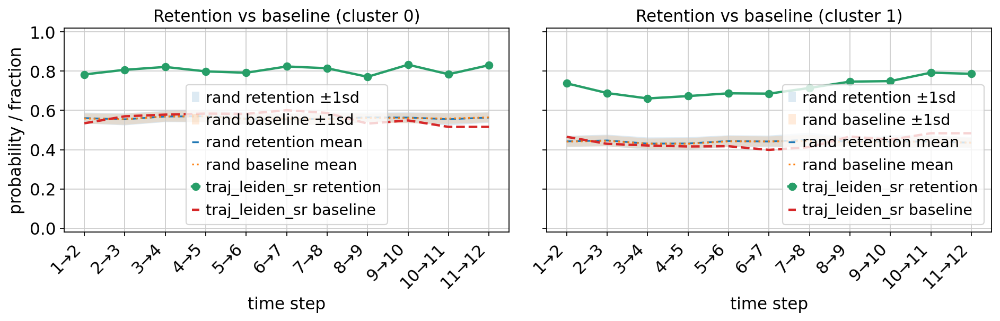

In [789]:
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt

# ============================================================
# Follow-up: retention vs random baseline (cluster-level curves)
#   Plots, for each cluster c:
#     - traj retention_c(t) (solid)
#     - traj baseline_c(t)  (dashed)
#     - random partitions retention mean±sd band
#     - random partitions baseline mean±sd band
# ============================================================

time_key = "time"
traj_key = "traj_leiden_sr"
n_reps = 30
eps = 1e-12

assert time_key in adata.obs
assert traj_key in adata.obs
assert "T_pruned" in globals() and sp.issparse(T_pruned)

# --- row-stochastic ---
T = T_pruned.tocsr().astype(np.float64)
rs = np.asarray(T.sum(axis=1)).ravel()
z = rs == 0
if np.any(z):
    T = T.copy().tocsr()
    T[z, z] = 1.0
    rs = np.asarray(T.sum(axis=1)).ravel()
T = sp.diags(1.0 / (rs + 1e-15)) @ T

# --- time bins ---
t = adata.obs[time_key]
tt = t.to_numpy().astype(object)
time_levels = list(t.cat.categories) if hasattr(t, "cat") else sorted(pd.unique(tt))
idx_by_time_all = [np.where(tt == lvl)[0] for lvl in time_levels]
idx_by_time = [ii for ii in idx_by_time_all if ii.size > 0]
time_levels_nonempty = [lvl for lvl, ii in zip(time_levels, idx_by_time_all) if ii.size > 0]
n_steps = len(idx_by_time) - 1
assert n_steps >= 1
x = np.arange(n_steps)
xlab = [f"{time_levels_nonempty[i]}→{time_levels_nonempty[i+1]}" for i in range(n_steps)]

def retention_vs_baseline_for_labels(labels01):
    labels01 = np.asarray(labels01, dtype=int)
    out = {
        "ret":  np.full((n_steps, 2), np.nan, dtype=float),
        "base": np.full((n_steps, 2), np.nan, dtype=float),
    }
    for ti in range(n_steps):
        idx_src = idx_by_time[ti]
        idx_dst = idx_by_time[ti+1]
        A = T[idx_src, :][:, idx_dst].tocsr()
        denom = np.asarray(A.sum(axis=1)).ravel()
        dst_lab = labels01[idx_dst]

        for c in (0, 1):
            src_mask = (labels01[idx_src] == c)
            if not np.any(src_mask):
                continue
            src_rows = np.where(src_mask)[0]
            total_out = float(denom[src_rows].sum())
            if total_out <= 0:
                continue

            base_c = float(np.mean(dst_lab == c))
            out["base"][ti, c] = base_c

            dst_mask_c = (dst_lab == c)
            same_mass = float(A[src_rows, :][:, np.where(dst_mask_c)[0]].sum()) if np.any(dst_mask_c) else 0.0
            out["ret"][ti, c] = same_mass / total_out
    return out

def stack_metric(stats_list, key):
    return np.stack([s[key] for s in stats_list], axis=0)  # (R, n_steps, 2)

# traj labels
traj_lab = adata.obs[traj_key].astype(str).to_numpy()
if not np.all(np.isin(traj_lab, ["0", "1"])):
    raise ValueError(f"{traj_key} must contain only '0'/'1'.")
traj_lab01 = traj_lab.astype(int)
traj_stats = retention_vs_baseline_for_labels(traj_lab01)

# random partitions preserving global p1
p1 = float(np.mean(traj_lab01 == 1))
m = int(round(p1 * adata.n_obs))
rng = np.random.default_rng(0)

rand_stats_all = []
for _ in range(n_reps):
    lab = np.zeros(adata.n_obs, dtype=int)
    idx1 = rng.choice(adata.n_obs, size=m, replace=False)
    lab[idx1] = 1
    rand_stats_all.append(retention_vs_baseline_for_labels(lab))

rand_ret  = stack_metric(rand_stats_all, "ret")
rand_base = stack_metric(rand_stats_all, "base")

rand_ret_mean  = np.nanmean(rand_ret, axis=0);  rand_ret_std  = np.nanstd(rand_ret, axis=0)
rand_base_mean = np.nanmean(rand_base, axis=0); rand_base_std = np.nanstd(rand_base, axis=0)

# plot
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for c, ax in enumerate(axes):
    # random bands
    ax.fill_between(x, rand_ret_mean[:, c]  - rand_ret_std[:, c],  rand_ret_mean[:, c]  + rand_ret_std[:, c],
                    alpha=0.15, label="rand retention ±1sd")
    ax.fill_between(x, rand_base_mean[:, c] - rand_base_std[:, c], rand_base_mean[:, c] + rand_base_std[:, c],
                    alpha=0.15, label="rand baseline ±1sd")

    ax.plot(x, rand_ret_mean[:, c],  linestyle="--", linewidth=1.5, label="rand retention mean")
    ax.plot(x, rand_base_mean[:, c], linestyle=":",  linewidth=1.5, label="rand baseline mean")

    # traj curves
    ax.plot(x, traj_stats["ret"][:, c],  marker="o", linewidth=2.0, label=f"{traj_key} retention")
    ax.plot(x, traj_stats["base"][:, c], linestyle="--", linewidth=2.0, label=f"{traj_key} baseline")

    ax.set_title(f"Retention vs baseline (cluster {c})")
    ax.set_ylim(-0.02, 1.02)
    ax.set_xticks(x)
    ax.set_xticklabels([str(s) for s in xlab], rotation=45, ha="right")
    ax.set_xlabel("time step")
    if c == 0:
        ax.set_ylabel("probability / fraction")
    ax.legend(loc="best")

plt.tight_layout()
plt.show()

In [794]:
import numpy as np
import pandas as pd
import scipy.sparse as sp

# ============================================================
# Mass retention (%) per cluster + baseline expected from cluster size
#
# For each step t -> t+1 and cluster c:
#   retention_c(t) = mass from cluster c@t landing in cluster c@t+1 / total mass from cluster c@t into t+1
#   baseline_c(t)  = fraction of DESTINATION cells (t+1) in cluster c   (size-only expectation)
#
# Overall (pooled across steps, mass-weighted):
#   overall_ret_c = sum_t same_mass_c(t) / sum_t total_out_mass_c(t)
#   overall_base_c = sum_t [ baseline_c(t) * total_out_mass_c(t) ] / sum_t total_out_mass_c(t)
#
# Stores:
#   adata.uns['cluster_ret_base_by_step'] : DataFrame with ret/base for each cluster
#   adata.uns['cluster_ret_base_overall'] : Series with overall ret/base for each cluster
# ============================================================

time_key = "time"
traj_key = "traj_leiden_sr"
eps = 1e-12

assert time_key in adata.obs, f"Need adata.obs['{time_key}']"
assert traj_key in adata.obs, f"Need adata.obs['{traj_key}']"
assert "T_pruned" in globals(), "Need T_pruned in scope."
assert sp.issparse(T_pruned), "T_pruned must be sparse."
assert T_pruned.shape == (adata.n_obs, adata.n_obs)

# --- row-stochastic forward kernel ---
T = T_pruned.tocsr().astype(np.float64)
rs = np.asarray(T.sum(axis=1)).ravel()
z = rs == 0
if np.any(z):
    T = T.copy().tocsr()
    T[z, z] = 1.0
    rs = np.asarray(T.sum(axis=1)).ravel()
T = sp.diags(1.0 / (rs + 1e-15)) @ T

# --- time bins ---
t = adata.obs[time_key]
tt = t.to_numpy().astype(object)
time_levels = list(t.cat.categories) if hasattr(t, "cat") else sorted(pd.unique(tt))
idx_by_time_all = [np.where(tt == lvl)[0] for lvl in time_levels]
idx_by_time = [ii for ii in idx_by_time_all if ii.size > 0]
time_levels_nonempty = [lvl for lvl, ii in zip(time_levels, idx_by_time_all) if ii.size > 0]
assert len(idx_by_time) >= 2, "Need at least 2 timepoints."

# --- labels 0/1 ---
lab = adata.obs[traj_key].astype(str).to_numpy()
if not np.all(np.isin(lab, ["0", "1"])):
    raise ValueError(f"{traj_key} must contain only '0'/'1'.")
lab01 = lab.astype(int)

n_steps = len(idx_by_time) - 1
step_names = [f"{time_levels_nonempty[i]}→{time_levels_nonempty[i+1]}" for i in range(n_steps)]

ret = np.full((n_steps, 2), np.nan, dtype=float)
base = np.full((n_steps, 2), np.nan, dtype=float)
total_out = np.full((n_steps, 2), np.nan, dtype=float)
same_mass = np.full((n_steps, 2), np.nan, dtype=float)

for ti in range(n_steps):
    idx_src = idx_by_time[ti]
    idx_dst = idx_by_time[ti + 1]

    A = T[idx_src, :][:, idx_dst].tocsr()
    denom = np.asarray(A.sum(axis=1)).ravel()  # per-cell outgoing to t+1

    dst_lab = lab01[idx_dst]
    frac0 = float(np.mean(dst_lab == 0))
    frac1 = 1.0 - frac0
    dst_mask0 = (dst_lab == 0)
    dst_mask1 = ~dst_mask0

    for c in (0, 1):
        src_mask = (lab01[idx_src] == c)
        if not np.any(src_mask):
            continue

        src_rows = np.where(src_mask)[0]
        tot = float(denom[src_rows].sum())
        total_out[ti, c] = tot
        if tot <= eps:
            continue

        # baseline: destination fraction in cluster c (size-only expectation)
        base_c = frac0 if c == 0 else frac1
        base[ti, c] = base_c

        # same-cluster mass
        dst_mask_c = dst_mask0 if c == 0 else dst_mask1
        sm = float(A[src_rows, :][:, np.where(dst_mask_c)[0]].sum()) if np.any(dst_mask_c) else 0.0
        same_mass[ti, c] = sm

        ret[ti, c] = sm / tot

# per-step table (percent)
df = pd.DataFrame(
    {
        "ret_cluster0_%": 100 * ret[:, 0],
        "base_cluster0_%": 100 * base[:, 0],
        "ret_cluster1_%": 100 * ret[:, 1],
        "base_cluster1_%": 100 * base[:, 1],
    },
    index=step_names,
)
adata.uns["cluster_ret_base_by_step"] = df

# overall pooled (mass-weighted over steps)
overall_ret = np.zeros(2, dtype=float)
overall_base = np.zeros(2, dtype=float)

for c in (0, 1):
    tot = np.nansum(total_out[:, c])
    if tot <= eps:
        overall_ret[c] = np.nan
        overall_base[c] = np.nan
        continue

    overall_ret[c] = np.nansum(same_mass[:, c]) / tot
    # expected same-cluster mass under baseline each step is base(t,c) * total_out(t,c)
    overall_base[c] = np.nansum(base[:, c] * total_out[:, c]) / tot

overall = pd.Series(
    {
        "overall_ret_cluster0_%": 100 * overall_ret[0],
        "overall_base_cluster0_%": 100 * overall_base[0],
        "overall_ret_cluster1_%": 100 * overall_ret[1],
        "overall_base_cluster1_%": 100 * overall_base[1],
    }
)
adata.uns["cluster_ret_base_overall"] = overall

print("Per-step retention vs baseline (%):")
print(df.round(2).to_string())

print("\nOverall (pooled, mass-weighted) retention vs baseline (%):")
print(overall.round(2).to_string())

Per-step retention vs baseline (%):
       ret_cluster0_%  base_cluster0_%  ret_cluster1_%  base_cluster1_%
1→2             78.32            53.45           73.79            46.55
2→3             80.69            57.00           68.84            43.00
3→4             82.14            57.86           66.10            42.14
4→5             79.88            58.36           67.29            41.64
5→6             79.18            58.24           68.71            41.76
6→7             82.38            60.10           68.55            39.90
7→8             81.47            58.71           71.42            41.29
8→9             77.12            53.29           74.67            46.71
9→10            83.28            54.90           74.93            45.10
10→11           78.42            51.61           79.22            48.39
11→12           83.03            51.62           78.65            48.38

Overall (pooled, mass-weighted) retention vs baseline (%):
overall_ret_cluster0_%     80.60
overall

/new-stg/home/alex/miniconda3/envs/wot2/lib/python3.13/site-packages/scipy/sparse/_index.py:210: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_arrayXarray(i, j, x)


In [ ]:
adata_full_out = adata_full[adata.obs_names, :].copy()
adata_full_out.obs = adata.obs.copy()
adata_full_out.obsm = adata.obsm.copy()
adata_full_out.obsp = adata.obsp.copy()
adata_full_out.uns = adata.uns.copy()

for _adata_to_write in (adata_full_out, adata):
    for _key, _value in list(_adata_to_write.uns.items()):
        if isinstance(_value, pd.Series):
            _adata_to_write.uns[_key] = _value.to_frame("value")

adata_full_out.write_h5ad('../output/adata_full.h5ad')
adata.write_h5ad('../output/adata_hvg.h5ad')
